# Light Shining Through the Moon 

In [1]:
%pip install -q numpy scipy matplotlib pandas astropy skyfield sgp4 geopack requests



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from datetime import timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from scipy.interpolate import interp1d
from scipy.integrate import trapezoid
from scipy.optimize import minimize, brentq

from astropy.io import fits
from skyfield.api import load, load_file, wgs84
from skyfield.framelib import itrs
from geopack import geopack, t89

from urllib.request import urlretrieve


# ---------------- physical configuration ----------------
GREF = 1.0e-10                      # GeV^-1
E_MIN, E_MAX = 3.0, 15.0           # keV
LEO_ALT_KM = 600.0                  # representative LEO detector altitude
ROI_ARCMIN = 4.0                    # angular radius of solar-axion ROI
THETA_ROI_RAD = np.deg2rad(ROI_ARCMIN / 60.0)
KP_FID = 2
KP_SCAN = [0, 2, 4]
PLASMA_FID = "fiducial"

# Legacy detector benchmark exposure. The propagated August orbit below determines
# its own physical occultation duration; do not use T_OCC for a final sensitivity forecast.
T_OCC = 300.0                       # s (legacy benchmark only)

# NuSTAR-like proof-of-concept detector.
RESPONSE_MODE = "proxy"             # "proxy" or "arf"
BACKGROUND_MODE = "proxy"           # "proxy" or "pha"
ARF_PATHS = []                      # final: ["nuA.arf","nuB.arf"]
BACKGROUND_PHA = None               # final: "background.pha"
# Background benchmark is specified as the TOTAL 3--15 keV rate inside a 4-arcmin-radius aperture.
# The detector model below converts it to a surface rate so that changing the ROI rescales B consistently.
BKG_TOTAL_3_15_REF = 2.0e-3        # count/s inside ROI_RADIUS_REF_ARCMIN
ROI_RADIUS_REF_ARCMIN = 4.0

# Numerical controls.
FAST = False
N_FIELD = 550 if FAST else 1200
N_E = 32 if FAST else 60
N_MASS = 42 if FAST else 75
PHASE_STEP = 0.10 if FAST else 0.05 # maximum phase advance per fine integration step [rad]
MASS_MAX = 1.0e-4                   # stop where numerical convergence remains controllable

# Constants.
RE_KM = 6371.2
TESLA_TO_EV2 = 195.0
M_TO_EVINV = 5.0677307e6
GEV_TO_EV = 1.0e9
R_SUN_KM = 695700.0
R_MOON_KM = 1737.4

# Local ephemeris: do not download inside the scientific calculation.
EPHEMERIS_PATH = Path("skyfield_data/de421.bsp")

FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

SINGLE = 3.35
DOUBLE = 7.0

plt.rcParams.update({
    "figure.figsize": (SINGLE, 2.55),
    "figure.dpi": 140,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "font.size": 8.0,
    "axes.labelsize": 8.5,
    "legend.fontsize": 7.0,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.1,
    "mathtext.fontset": "stix",
    "font.family": "serif",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


Load IGRF coefficients ...


## Local JPL ephemeris and fiducial eclipse epoch

The main calculation uses the 12 Aug 2026 total eclipse only as a convenient, demonstrably realizable Sun–Moon alignment. The spacecraft itself is generic.

Place `de421.bsp` in `skyfield_data/de421.bsp`.

In [3]:
if not EPHEMERIS_PATH.exists():
    raise FileNotFoundError(
        f"Missing {EPHEMERIS_PATH}. Download de421.bsp once and place it there."
    )

ts = load.timescale()
eph = load_file(str(EPHEMERIS_PATH))
earth, sun, moon = eph["earth"], eph["sun"], eph["moon"]

# Near greatest eclipse, 12 Aug 2026.
t_occ = ts.utc(2026, 8, 12, 17, 45, 54)

print("Fiducial epoch:", t_occ.utc_iso())


Fiducial epoch: 2026-08-12T17:45:54Z


##  Solve for a physically realizable LEO occultation position

At fixed altitude \(h=600\) km, we solve for the observer latitude/longitude that minimizes the apparent Sun–Moon separation.


In [4]:
def topocentric_vectors(lat_deg, lon_deg, t=t_occ, altitude_km=LEO_ALT_KM):
    rsat = wgs84.latlon(
        latitude_degrees=lat_deg,
        longitude_degrees=lon_deg,
        elevation_m=altitude_km*1e3
    ).at(t).position.km

    rsun = earth.at(t).observe(sun).apparent().position.km.reshape(3)
    rmoon = earth.at(t).observe(moon).apparent().position.km.reshape(3)

    vs = rsun - rsat
    vm = rmoon - rsat
    return rsat, vs, vm

def angle_between(a,b):
    return np.arccos(np.clip(np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b)),-1,1))

def separation_objective(x):
    lat,lon=x
    _,vs,vm=topocentric_vectors(lat,lon)
    return angle_between(vs,vm)

# Start near NASA's greatest-eclipse ground point.
res = minimize(
    separation_objective,
    x0=np.array([65.2,-25.2]),
    method="Nelder-Mead",
    options={"xatol":1e-8,"fatol":1e-12,"maxiter":2000}
)

LAT_FID, LON_FID = res.x
rsat_fid, vs_fid, vm_fid = topocentric_vectors(LAT_FID,LON_FID)

sep = angle_between(vs_fid,vm_fid)
sun_rad = np.arcsin(R_SUN_KM/np.linalg.norm(vs_fid))
moon_rad = np.arcsin(R_MOON_KM/np.linalg.norm(vm_fid))

SUN_RADIUS_ARCMIN = np.rad2deg(sun_rad)*60.0
RHO_ROI = ROI_ARCMIN / SUN_RADIUS_ARCMIN

print(f"Fiducial LEO latitude  : {LAT_FID:.5f} deg")
print(f"Fiducial LEO longitude : {LON_FID:.5f} deg")
print(f"Sun-Moon separation    : {np.rad2deg(sep)*60:.4f} arcmin")
print(f"Sun angular radius     : {np.rad2deg(sun_rad)*60:.4f} arcmin")
print(f"Moon angular radius    : {np.rad2deg(moon_rad)*60:.4f} arcmin")
print(f"ROI angular radius     : {ROI_ARCMIN:.4f} arcmin")
print(f"ROI projected radius   : rho = {RHO_ROI:.5f} R_sun")
print("Central ROI occulted   :", sep + np.deg2rad(ROI_ARCMIN/60) < moon_rad)
print("Full disk occulted     :", sep + sun_rad < moon_rad)


Fiducial LEO latitude  : 60.88469 deg
Fiducial LEO longitude : -42.27608 deg
Sun-Moon separation    : 0.0000 arcmin
Sun angular radius     : 15.7779 arcmin
Moon angular radius    : 16.4553 arcmin
ROI angular radius     : 4.0000 arcmin
ROI projected radius   : rho = 0.25352 R_sun
Central ROI occulted   : True
Full disk occulted     : True


## Solar line of sight and geomagnetic field

In [5]:
def unix_time_from_skyfield(t):
    return t.utc_datetime().replace(tzinfo=timezone.utc).timestamp()


def vec_geo_to_gsm(v):
    return np.array(
        geopack.geogsm(float(v[0]), float(v[1]), float(v[2]), 1)
    )


def solar_los_gsm(
    t=t_occ,
    lat=LAT_FID,
    lon=LON_FID,
    altitude_km=LEO_ALT_KM,
    rmax_re=15.0,
    npts=N_FIELD,
):
    rsat, vs, _ = topocentric_vectors(lat, lon, t, altitude_km)
    nhat = vs / np.linalg.norm(vs)

    target = rmax_re * RE_KM
    b = np.dot(rsat, nhat)
    c = np.dot(rsat, rsat) - target**2
    disc = max(b*b - c, 0.0)
    roots = [r for r in (-b + np.sqrt(disc), -b - np.sqrt(disc)) if r > 0]
    smax = min(roots) if roots else 12 * RE_KM

    s_km = np.linspace(0, smax, npts)
    pts_gcrs = rsat[:, None] + nhat[:, None] * s_km[None, :]

    R = itrs.rotation_at(t)
    pts_geo_re = (R @ pts_gcrs) / RE_KM

    geopack.recalc(unix_time_from_skyfield(t))
    pts_gsm = np.array([
        vec_geo_to_gsm(pts_geo_re[:, i]) for i in range(npts)
    ])

    dxyz = np.gradient(pts_gsm, axis=0)
    tang = dxyz / np.linalg.norm(dxyz, axis=1)[:, None]

    return s_km * 1e3, pts_gsm, tang


def kp_to_t89_iopt(Kp):
    return int(np.clip(round(Kp) + 1, 1, 7))


def _fixed_transverse_basis(tang):
    """Return a fixed orthonormal basis (e1,e2,ell) for one LOS."""
    ell = np.mean(tang, axis=0)
    ell = ell / np.linalg.norm(ell)

    ref = np.array([0.0, 0.0, 1.0])
    if abs(np.dot(ref, ell)) > 0.9:
        ref = np.array([1.0, 0.0, 0.0])

    e1 = np.cross(ell, ref)
    e1 = e1 / np.linalg.norm(e1)

    e2 = np.cross(ell, e1)
    e2 = e2 / np.linalg.norm(e2)

    return e1, e2, ell


def build_field_profile(Kp=2):
    s_m, xyz, tang = solar_los_gsm()
    ps = geopack.recalc(unix_time_from_skyfield(t_occ))
    iopt = kp_to_t89_iopt(Kp)

    B = np.zeros_like(xyz)
    for i, (x, y, z) in enumerate(xyz):
        bi = np.array(geopack.igrf_gsm(float(x), float(y), float(z)))
        be = np.array(t89.t89(iopt, ps, float(x), float(y), float(z)))
        B[i] = (bi + be) * 1e-9  # nT -> T

    e1, e2, ell = _fixed_transverse_basis(tang)

    # Signed transverse components. These enter the physical amplitudes.
    B1 = B @ e1
    B2 = B @ e2

    # Positive magnitude retained only for diagnostics / plotting.
    Bperp_mag = np.sqrt(B1**2 + B2**2)

    return {
        "s_m": s_m,
        "r_re": np.linalg.norm(xyz, axis=1),
        "B1_T": B1,
        "B2_T": B2,
        "Bperp_mag_T": Bperp_mag,
        "B_T": B,
        "ell": ell,
        "e1": e1,
        "e2": e2,
        "Kp": Kp,
    }


# Expensive field calculation occurs only here.
FIELD = {kp: build_field_profile(kp) for kp in KP_SCAN}

# Compare the old scalar magnitude integral against the coherent vector lever arm.
for kp, p in FIELD.items():
    IB_abs = trapezoid(p["Bperp_mag_T"], p["s_m"])
    IB1 = trapezoid(p["B1_T"], p["s_m"])
    IB2 = trapezoid(p["B2_T"], p["s_m"])
    IB_vec = np.hypot(IB1, IB2)

    print(f"Kp = {kp}")
    print(f"  int |B_perp| ds = {IB_abs:.6e} T m")
    print(f"  int B1 ds       = {IB1:.6e} T m")
    print(f"  int B2 ds       = {IB2:.6e} T m")
    print(f"  vector I_B      = {IB_vec:.6e} T m")
    print(f"  ratio           = {IB_vec/IB_abs:.6f}")
    print(
        "  basis checks:",
        f"e1.l={np.dot(p['e1'], p['ell']):.2e},",
        f"e2.l={np.dot(p['e2'], p['ell']):.2e},",
        f"e1.e2={np.dot(p['e1'], p['e2']):.2e}",
    )
    print()


Kp = 0
  int |B_perp| ds = 8.716463e+01 T m
  int B1 ds       = 6.173996e+01 T m
  int B2 ds       = 3.702249e+01 T m
  vector I_B      = 7.198949e+01 T m
  ratio           = 0.825903
  basis checks: e1.l=0.00e+00, e2.l=0.00e+00, e1.e2=0.00e+00

Kp = 2
  int |B_perp| ds = 8.753191e+01 T m
  int B1 ds       = 6.175293e+01 T m
  int B2 ds       = 3.680474e+01 T m
  vector I_B      = 7.188890e+01 T m
  ratio           = 0.821288
  basis checks: e1.l=0.00e+00, e2.l=0.00e+00, e1.e2=0.00e+00

Kp = 4
  int |B_perp| ds = 8.784414e+01 T m
  int B1 ds       = 6.177697e+01 T m
  int B2 ds       = 3.671877e+01 T m
  vector I_B      = 7.186558e+01 T m
  ratio           = 0.818103
  basis checks: e1.l=0.00e+00, e2.l=0.00e+00, e1.e2=0.00e+00



## Propagated physical LEO orbit

We construct a circular near-600-km orbit that passes through the fiducial lunar-occultation position at the reference eclipse epoch. The orbit is propagated with two-body Keplerian dynamics


In [6]:
# ==============================================================
# Physical circular orbit through the fiducial occultation
# ==============================================================

MU_EARTH_KM3_S2 = 398600.4418
DAY_S = 86400.0

r0_orbit = np.asarray(rsat_fid, dtype=float)
a_orbit_km = np.linalg.norm(r0_orbit)
rhat0 = r0_orbit / a_orbit_km

# Choose a polar orbital plane through the fiducial point.
zhat = np.array([0.0, 0.0, 1.0])
hhat = np.cross(zhat, rhat0)
if np.linalg.norm(hhat) < 1e-12:
    hhat = np.array([1.0, 0.0, 0.0])
else:
    hhat = hhat / np.linalg.norm(hhat)

vhat0 = np.cross(hhat, rhat0)
vhat0 = vhat0 / np.linalg.norm(vhat0)

n_orbit = np.sqrt(MU_EARTH_KM3_S2 / a_orbit_km**3)
v_circ_kms = np.sqrt(MU_EARTH_KM3_S2 / a_orbit_km)
period_orbit_s = 2.0 * np.pi / n_orbit
v0_orbit = v_circ_kms * vhat0

inclination_deg = np.rad2deg(
    np.arccos(np.clip(hhat[2], -1.0, 1.0))
)

print("=== PROPAGATED ORBIT ===")
print(f"Epoch               : {t_occ.utc_iso()}")
print(f"Orbital radius      : {a_orbit_km:.3f} km")
print(f"Approx. altitude    : {a_orbit_km - RE_KM:.3f} km")
print(f"Circular speed      : {v_circ_kms:.4f} km/s")
print(f"Orbital period      : {period_orbit_s/60:.3f} min")
print(f"Inclination         : {inclination_deg:.3f} deg")
print()
print("Initial position [km]:", r0_orbit)
print("Initial velocity [km/s]:", v0_orbit)


=== PROPAGATED ORBIT ===
Epoch               : 2026-08-12T17:45:54Z
Orbital radius      : 6961.845 km
Approx. altitude    : 590.645 km
Circular speed      : 7.5667 km/s
Orbital period      : 96.349 min
Inclination         : 90.000 deg

Initial position [km]: [-3374.27115207  -299.27266771  6082.10665965]
Initial velocity [km/s]: [-6.58468314 -0.58401225 -3.68183041]


In [7]:
def orbit_state(dt_s):
    """Analytic two-body propagation of the circular orbit."""
    u = n_orbit * dt_s
    cu = np.cos(u)
    su = np.sin(u)

    r_km = a_orbit_km * (rhat0 * cu + vhat0 * su)
    v_kms = v_circ_kms * (-rhat0 * su + vhat0 * cu)
    return r_km, v_kms


def time_from_dt(dt_s):
    return ts.tt_jd(t_occ.tt + dt_s / DAY_S)


for dt in [-300.0, 0.0, 300.0]:
    r, v = orbit_state(dt)
    print(
        f"dt={dt:+6.0f} s  "
        f"|r|={np.linalg.norm(r):.3f} km  "
        f"|v|={np.linalg.norm(v):.5f} km/s"
    )


dt=  -300 s  |r|=6961.845 km  |v|=7.56670 km/s
dt=    +0 s  |r|=6961.845 km  |v|=7.56670 km/s
dt=  +300 s  |r|=6961.845 km  |v|=7.56670 km/s


In [8]:
# ==============================================================
# Sun-Moon occultation geometry along the propagated orbit
# ==============================================================

def occultation_geometry_from_state(t, rsat_km):
    rsun = earth.at(t).observe(sun).apparent().position.km.reshape(3)
    rmoon = earth.at(t).observe(moon).apparent().position.km.reshape(3)

    vs = rsun - rsat_km
    vm = rmoon - rsat_km

    sep = angle_between(vs, vm)
    moon_rad = np.arcsin(R_MOON_KM / np.linalg.norm(vm))
    sun_rad = np.arcsin(R_SUN_KM / np.linalg.norm(vs))

    roi_occulted = sep + THETA_ROI_RAD < moon_rad
    full_sun_occulted = sep + sun_rad < moon_rad

    # Verify that the Sun-directed ray from the satellite does not intersect Earth.
    nhat = vs / np.linalg.norm(vs)
    s_closest = max(0.0, -np.dot(rsat_km, nhat))
    r_closest = np.linalg.norm(rsat_km + s_closest * nhat)
    earth_clear = r_closest > RE_KM

    return {
        "sep_rad": sep,
        "moon_rad": moon_rad,
        "sun_rad": sun_rad,
        "roi_occulted": roi_occulted,
        "full_sun_occulted": full_sun_occulted,
        "earth_clear": earth_clear,
        "r_closest_km": r_closest,
    }


DT_ORBIT = 10.0
HALF_WINDOW = 600.0
dt_orbit = np.arange(-HALF_WINDOW, HALF_WINDOW + DT_ORBIT, DT_ORBIT)

geometry_rows = []
for dt in dt_orbit:
    t = time_from_dt(dt)
    r_sat, _ = orbit_state(dt)
    geo = occultation_geometry_from_state(t, r_sat)

    geometry_rows.append({
        "dt_s": dt,
        "sep_arcmin": np.rad2deg(geo["sep_rad"]) * 60.0,
        "moon_radius_arcmin": np.rad2deg(geo["moon_rad"]) * 60.0,
        "roi_occulted": geo["roi_occulted"],
        "full_sun_occulted": geo["full_sun_occulted"],
        "earth_clear": geo["earth_clear"],
    })

ORBIT_GEOM = pd.DataFrame(geometry_rows)
valid = ORBIT_GEOM["roi_occulted"] & ORBIT_GEOM["earth_clear"]

print("Number of valid orbital samples:", valid.sum())
if valid.any():
    t_first = ORBIT_GEOM.loc[valid, "dt_s"].iloc[0]
    t_last = ORBIT_GEOM.loc[valid, "dt_s"].iloc[-1]
    print(f"ROI-occulted interval: {t_first:+.0f} to {t_last:+.0f} s")
    print(f"Approximate duration: {t_last-t_first:.0f} s")
else:
    print("WARNING: this orbital plane does not produce a finite ROI-occulted window.")


Number of valid orbital samples: 48
ROI-occulted interval: -250 to +220 s
Approximate duration: 470 s


In [9]:
# ==============================================================
# Magnetic LOS for an arbitrary propagated spacecraft state
# ==============================================================

def solar_los_gsm_from_state(t, rsat_km, rmax_re=15.0, npts=None):
    if npts is None:
        npts = 300 if FAST else 600

    rsun = earth.at(t).observe(sun).apparent().position.km.reshape(3)
    vs = rsun - rsat_km
    nhat = vs / np.linalg.norm(vs)

    target = rmax_re * RE_KM
    b = np.dot(rsat_km, nhat)
    c = np.dot(rsat_km, rsat_km) - target**2
    disc = max(b*b - c, 0.0)
    roots = [r for r in (-b + np.sqrt(disc), -b - np.sqrt(disc)) if r > 0]
    smax = min(roots) if roots else 12.0 * RE_KM

    s_km = np.linspace(0.0, smax, npts)
    pts_gcrs = rsat_km[:, None] + nhat[:, None] * s_km[None, :]

    R = itrs.rotation_at(t)
    pts_geo_re = (R @ pts_gcrs) / RE_KM

    geopack.recalc(unix_time_from_skyfield(t))
    pts_gsm = np.array([
        vec_geo_to_gsm(pts_geo_re[:, i]) for i in range(npts)
    ])

    dxyz = np.gradient(pts_gsm, axis=0)
    tang = dxyz / np.linalg.norm(dxyz, axis=1)[:, None]
    return s_km * 1e3, pts_gsm, tang


def build_field_profile_from_state(t, rsat_km, Kp=KP_FID, npts=None):
    s_m, xyz, tang = solar_los_gsm_from_state(t, rsat_km, npts=npts)
    ps = geopack.recalc(unix_time_from_skyfield(t))
    iopt = kp_to_t89_iopt(Kp)

    B = np.zeros_like(xyz)
    for i, (x, y, z) in enumerate(xyz):
        bi = np.array(geopack.igrf_gsm(float(x), float(y), float(z)))
        be = np.array(t89.t89(iopt, ps, float(x), float(y), float(z)))
        B[i] = (bi + be) * 1e-9

    e1, e2, ell = _fixed_transverse_basis(tang)
    B1 = B @ e1
    B2 = B @ e2

    return {
        "s_m": s_m,
        "r_re": np.linalg.norm(xyz, axis=1),
        "B1_T": B1,
        "B2_T": B2,
        "Bperp_mag_T": np.sqrt(B1**2 + B2**2),
        "B_T": B,
        "ell": ell,
        "e1": e1,
        "e2": e2,
        "Kp": Kp,
    }


def coherent_IB(profile):
    IB1 = trapezoid(profile["B1_T"], profile["s_m"])
    IB2 = trapezoid(profile["B2_T"], profile["s_m"])
    return IB1, IB2, np.hypot(IB1, IB2)


In [10]:
# ==============================================================
# Consistency check at the orbital anchor epoch
# ==============================================================

r_anchor, _ = orbit_state(0.0)
PROFILE_ORBIT_0 = build_field_profile_from_state(t_occ, r_anchor, Kp=KP_FID)
IB1_0, IB2_0, IB_0 = coherent_IB(PROFILE_ORBIT_0)
IB1_fid, IB2_fid, IB_fid = coherent_IB(FIELD[KP_FID])

print("=== ANCHOR CONSISTENCY CHECK ===")
print(f"Propagated-state I_B = {IB_0:.6f} T m")
print(f"Original fiducial I_B = {IB_fid:.6f} T m")
reldiff = abs(IB_0 - IB_fid) / max(IB_fid, 1e-30)
print(f"Relative difference = {100*reldiff:.4f} %")


=== ANCHOR CONSISTENCY CHECK ===
Propagated-state I_B = 71.904392 T m
Original fiducial I_B = 71.888896 T m
Relative difference = 0.0216 %


In [11]:
# ==============================================================
# I_B(t) along the physical orbit
# ==============================================================

orbit_results = []
NPTS_ORBIT_FIELD = 250 if FAST else 550

for j, dt in enumerate(dt_orbit):
    t = time_from_dt(dt)
    r_sat, _ = orbit_state(dt)
    geo = occultation_geometry_from_state(t, r_sat)

    profile = build_field_profile_from_state(
        t, r_sat, Kp=KP_FID, npts=NPTS_ORBIT_FIELD
    )
    IB1, IB2, IB = coherent_IB(profile)

    orbit_results.append({
        "dt_s": dt,
        "IB1_Tm": IB1,
        "IB2_Tm": IB2,
        "IB_Tm": IB,
        "sep_arcmin": np.rad2deg(geo["sep_rad"]) * 60.0,
        "moon_radius_arcmin": np.rad2deg(geo["moon_rad"]) * 60.0,
        "roi_occulted": geo["roi_occulted"],
        "earth_clear": geo["earth_clear"],
        "radius_km": np.linalg.norm(r_sat),
    })

    if j % 10 == 0:
        print(
            f"{j+1:3d}/{len(dt_orbit)}  "
            f"dt={dt:+6.0f} s  "
            f"I_B={IB:8.3f} T m"
        )

ORBIT_RESULT = pd.DataFrame(orbit_results)

valid_orbit = ORBIT_RESULT["roi_occulted"] & ORBIT_RESULT["earth_clear"]
print()
print("=== PHYSICAL OCCULTATION WINDOW ===")
if valid_orbit.any():
    data_valid = ORBIT_RESULT.loc[valid_orbit]
    print(f"Start : {data_valid['dt_s'].iloc[0]:+.0f} s")
    print(f"End   : {data_valid['dt_s'].iloc[-1]:+.0f} s")
    print(
        f"Duration ~= "
        f"{data_valid['dt_s'].iloc[-1]-data_valid['dt_s'].iloc[0]:.0f} s"
    )
    print(f"I_B minimum = {data_valid['IB_Tm'].min():.3f} T m")
    print(f"I_B maximum = {data_valid['IB_Tm'].max():.3f} T m")
    print(f"I_B mean    = {data_valid['IB_Tm'].mean():.3f} T m")
    imax = data_valid["IB_Tm"].idxmax()
    print(f"Maximum at dt = {ORBIT_RESULT.loc[imax, 'dt_s']:+.0f} s")
else:
    raise RuntimeError("No ROI-occulted interval found along the propagated orbit.")


  1/121  dt=  -600 s  I_B= 161.209 T m
 11/121  dt=  -500 s  I_B= 139.792 T m
 21/121  dt=  -400 s  I_B= 120.614 T m
 31/121  dt=  -300 s  I_B= 103.831 T m
 41/121  dt=  -200 s  I_B=  89.738 T m
 51/121  dt=  -100 s  I_B=  78.874 T m
 61/121  dt=    +0 s  I_B=  71.908 T m
 71/121  dt=  +100 s  I_B=  69.201 T m
 81/121  dt=  +200 s  I_B=  70.299 T m
 91/121  dt=  +300 s  I_B=  73.977 T m
101/121  dt=  +400 s  I_B=  78.782 T m
111/121  dt=  +500 s  I_B=  83.482 T m
121/121  dt=  +600 s  I_B=  87.208 T m

=== PHYSICAL OCCULTATION WINDOW ===
Start : -250 s
End   : +220 s
Duration ~= 470 s
I_B minimum = 69.147 T m
I_B maximum = 96.420 T m
I_B mean    = 76.611 T m
Maximum at dt = -250 s


In [12]:
# ==============================================================
# Signal-weighted magnetic exposure along the propagated orbit
# ==============================================================

valid = (
    ORBIT_RESULT["roi_occulted"].to_numpy(dtype=bool)
    & ORBIT_RESULT["earth_clear"].to_numpy(dtype=bool)
)

t_valid = ORBIT_RESULT.loc[valid, "dt_s"].to_numpy(dtype=float)
IB_valid = ORBIT_RESULT.loc[valid, "IB_Tm"].to_numpy(dtype=float)

if len(t_valid) < 2:
    raise RuntimeError("Not enough valid occulted samples.")

T_valid = t_valid[-1] - t_valid[0]
magnetic_exposure = trapezoid(IB_valid**2, t_valid)
IB_rms = np.sqrt(magnetic_exposure / T_valid)
IB_mean = trapezoid(IB_valid, t_valid) / T_valid

T_benchmark = 300.0
IB_equiv_300 = np.sqrt(magnetic_exposure / T_benchmark)

print("=== SIGNAL-WEIGHTED ORBITAL EXPOSURE ===")
print(f"Occulted duration          = {T_valid:.1f} s")
print(f"<I_B>                     = {IB_mean:.3f} T m")
print(f"I_B,rms                   = {IB_rms:.3f} T m")
print(f"Integral I_B^2 dt         = {magnetic_exposure:.6e} (T m)^2 s")
print(f"Equivalent I_B for 300 s  = {IB_equiv_300:.3f} T m")


=== SIGNAL-WEIGHTED ORBITAL EXPOSURE ===
Occulted duration          = 470.0 s
<I_B>                     = 76.461 T m
I_B,rms                   = 76.888 T m
Integral I_B^2 dt         = 2.778552e+06 (T m)^2 s
Equivalent I_B for 300 s  = 96.238 T m


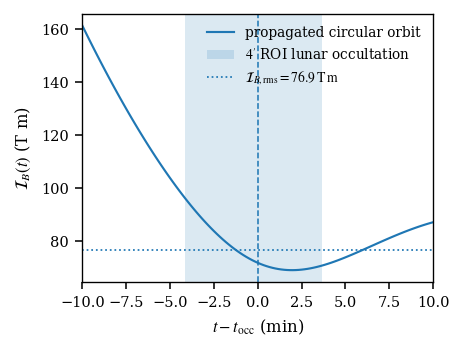

In [13]:
# ==============================================================
# Supplemental figure: propagated-orbit magnetic lever arm
# ============================================================== 

fig, ax = plt.subplots(figsize=(SINGLE, 2.55))

ax.plot(
    ORBIT_RESULT["dt_s"] / 60.0,
    ORBIT_RESULT["IB_Tm"],
    label=r"propagated circular orbit",
)

valid_plot = ORBIT_RESULT["roi_occulted"] & ORBIT_RESULT["earth_clear"]
t0_plot = ORBIT_RESULT.loc[valid_plot, "dt_s"].iloc[0] / 60.0
t1_plot = ORBIT_RESULT.loc[valid_plot, "dt_s"].iloc[-1] / 60.0

ax.axvspan(
    t0_plot,
    t1_plot,
    alpha=0.16,
    label=r"$4'$ ROI lunar occultation",
)
ax.axhline(
    IB_rms,
    ls=":",
    lw=0.9,
    label=fr"$\mathcal{{I}}_{{B,\rm rms}}={IB_rms:.1f}\,\mathrm{{T\,m}}$",
)
ax.axvline(0.0, ls="--", lw=0.8)

ax.set_xlabel(r"$t-t_{\rm occ}$ (min)")
ax.set_ylabel(r"$\mathcal{I}_B(t)$ (T m)")
ax.set_xlim(-10, 10)
ax.legend(frameon=False, loc="best")
fig.tight_layout()

fig.savefig(FIGDIR / "Supp_propagated_orbit_IB.pdf")
fig.savefig(FIGDIR / "Supp_propagated_orbit_IB.png")
plt.show()


## Magnetospheric plasma

In [14]:
def electron_density_cm3(r_re,Kp=2,model="fiducial"):
    r=np.asarray(r_re,float)
    Lpp=np.clip(5.6-0.46*Kp,2.5,6.0)
    ne_pl=10**(3.9043-0.3145*r)
    ne_out=5.0*(np.maximum(r,1.0)/10.0)**(-2)

    if model=="low":
        ne_pl*=0.35
        ne_out*=0.5
    elif model=="high":
        ne_pl*=3.0
        ne_out*=2.0

    w=1/(1+np.exp((r-Lpp)/0.18))
    return np.clip(w*ne_pl+(1-w)*ne_out,1e-4,1e5)

def omega_plasma_eV(ne_cm3):
    return 3.69e-11*np.sqrt(np.asarray(ne_cm3))


##  Phase-resolved conversion integral

The two signed transverse components $B_1(s)$ and $B_2(s)$ are interpolated onto a fine phase grid. The conversion probability is obtained from the two complex amplitudes and summed over unresolved final photon polarizations. This preserves cancellations from changes in transverse-field orientation.


In [15]:
def probability_from_profile(
    profile,
    ma_eV,
    E_keV,
    g=GREF,
    plasma_model=PLASMA_FID,
    phase_step=PHASE_STEP,
):
    s0 = np.asarray(profile["s_m"], dtype=float)
    B10 = np.asarray(profile["B1_T"], dtype=float)
    B20 = np.asarray(profile["B2_T"], dtype=float)
    r0 = np.asarray(profile["r_re"], dtype=float)
    kp = profile["Kp"]

    if not (len(s0) == len(B10) == len(B20) == len(r0)):
        raise ValueError("Field-profile arrays have inconsistent lengths.")

    ne0 = electron_density_cm3(r0, kp, plasma_model)
    wpl0 = omega_plasma_eV(ne0)
    E_eV = E_keV * 1e3
    q0 = (ma_eV**2 - wpl0**2) / (2.0 * E_eV)

    L_ev = (s0[-1] - s0[0]) * M_TO_EVINV
    total_phase_bound = np.max(np.abs(q0)) * L_ev
    n_phase = int(np.ceil(total_phase_bound / max(phase_step, 1e-4))) + 2
    n_fine = min(max(len(s0), n_phase), 60000)

    sf = np.linspace(s0[0], s0[-1], n_fine)
    B1f = np.interp(sf, s0, B10)
    B2f = np.interp(sf, s0, B20)
    rf = np.interp(sf, s0, r0)

    nef = electron_density_cm3(rf, kp, plasma_model)
    wpl = omega_plasma_eV(nef)
    q = (ma_eV**2 - wpl**2) / (2.0 * E_eV)

    s_ev = sf * M_TO_EVINV
    ds_ev = np.diff(s_ev)
    phase = np.zeros(len(sf))
    phase[1:] = np.cumsum(0.5 * (q[1:] + q[:-1]) * ds_ev)
    phase_factor = np.exp(1j * phase)

    I1 = trapezoid(B1f * TESLA_TO_EV2 * phase_factor, s_ev)
    I2 = trapezoid(B2f * TESLA_TO_EV2 * phase_factor, s_ev)

    g_eVinv = g / GEV_TO_EV
    P = 0.25 * g_eVinv**2 * (np.abs(I1)**2 + np.abs(I2)**2)
    return float(np.real(P))


# Minimal sanity check before convergence / figures.
p_test = FIELD[KP_FID]
P_test = probability_from_profile(p_test, ma_eV=1e-8, E_keV=5.0)
print("P test =", P_test)
assert np.isfinite(P_test) and P_test >= 0
print("Vector probability function OK")


P test = 1.2617110748273466e-17
Vector probability function OK


## Numerical convergence check

In [16]:
test_masses = [3e-5, 1e-4]
test_E = 3.0
steps = [0.20, 0.10, 0.05]

print("Numerical convergence test")
print("Kp =", KP_FID)
print()

for ma in test_masses:
    vals = []
    for st in steps:
        P = probability_from_profile(
            FIELD[KP_FID],
            ma_eV=ma,
            E_keV=test_E,
            g=GREF,
            plasma_model=PLASMA_FID,
            phase_step=st,
        )
        vals.append(P)

    vals = np.asarray(vals, dtype=float)
    rel = abs(vals[-1] - vals[-2]) / max(abs(vals[-1]), 1e-300)

    print(f"m_a = {ma:.1e} eV")
    for st, P in zip(steps, vals):
        print(f"  phase_step = {st:.2f} rad   P = {P:.6e}")
    print(f"  relative change (0.10 -> 0.05) = {100*rel:.4f} %")

    if rel < 0.01:
        print("  convergence: EXCELLENT")
    elif rel < 0.05:
        print("  convergence: ACCEPTABLE")
    else:
        print("  convergence: NEEDS FINER GRID")
    print()


Numerical convergence test
Kp = 2

m_a = 3.0e-05 eV
  phase_step = 0.20 rad   P = 3.624470e-18
  phase_step = 0.10 rad   P = 3.624470e-18
  phase_step = 0.05 rad   P = 3.625279e-18
  relative change (0.10 -> 0.05) = 0.0223 %
  convergence: EXCELLENT

m_a = 1.0e-04 eV
  phase_step = 0.20 rad   P = 3.535834e-20
  phase_step = 0.10 rad   P = 3.553522e-20
  phase_step = 0.05 rad   P = 3.557954e-20
  relative change (0.10 -> 0.05) = 0.1246 %
  convergence: EXCELLENT



## MAIN FIGURE 2 — phase-resolved conversion on the propagated orbit



Fig. 2 propagated-orbit sample: dt=-250 s, I_B=96.403 T m
Computing Fig. 2, E=3.0 keV ...
Computing Fig. 2, E=5.0 keV ...
Computing Fig. 2, E=8.0 keV ...


/tmp/ipykernel_8320/2766396711.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


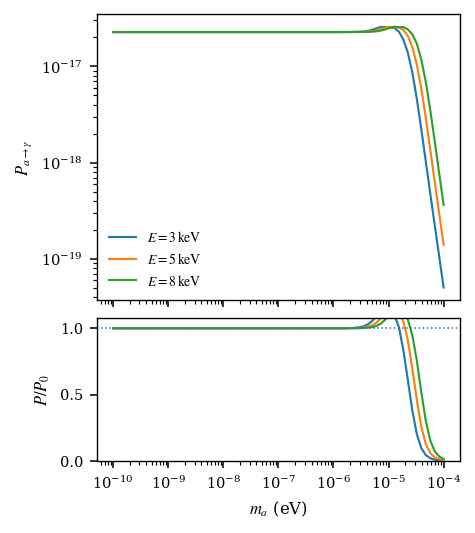

In [17]:
# ==============================================================
# MAIN FIGURE 2 — conversion probability and coherence
# ============================================================== 

# Representative *physical-orbit* LOS: maximum I_B while the 4' ROI is occulted.
valid_fig2 = ORBIT_RESULT["roi_occulted"] & ORBIT_RESULT["earth_clear"]
idx_fig2 = ORBIT_RESULT.loc[valid_fig2, "IB_Tm"].idxmax()
dt_fig2 = float(ORBIT_RESULT.loc[idx_fig2, "dt_s"])

t_fig2 = time_from_dt(dt_fig2)
r_fig2, _ = orbit_state(dt_fig2)
PROFILE_FIG2 = build_field_profile_from_state(
    t_fig2,
    r_fig2,
    Kp=KP_FID,
    npts=N_FIELD,
)

_, _, IB_fig2 = coherent_IB(PROFILE_FIG2)
print(f"Fig. 2 propagated-orbit sample: dt={dt_fig2:+.0f} s, I_B={IB_fig2:.3f} T m")

m_prob = np.logspace(-10, np.log10(MASS_MAX), 45 if FAST else 75)
energies_plot = [3.0, 5.0, 8.0]

fig, (ax, axc) = plt.subplots(
    2, 1,
    figsize=(SINGLE, 4.15),
    sharex=True,
    gridspec_kw={"height_ratios": [2.0, 1.0], "hspace": 0.08},
)

for E in energies_plot:
    print(f"Computing Fig. 2, E={E:.1f} keV ...")
    vals = np.array([
        probability_from_profile(
            PROFILE_FIG2,
            ma_eV=ma,
            E_keV=E,
            g=GREF,
            plasma_model=PLASMA_FID,
            phase_step=PHASE_STEP,
        )
        for ma in m_prob
    ], dtype=float)

    if not np.all(np.isfinite(vals)) or np.any(vals < 0):
        raise RuntimeError(f"Invalid probabilities for E={E} keV")

    # Low-mass plateau from the first few points; robust against tiny numerical noise.
    P0 = np.median(vals[:5])
    coherence = np.clip(vals / max(P0, 1e-300), 1e-8, None)

    ax.loglog(m_prob, vals, label=fr"$E={E:g}\,\mathrm{{keV}}$")
    axc.semilogx(m_prob, coherence)

ax.set_ylabel(r"$P_{a\to\gamma}$")
ax.legend(frameon=False, loc="best")

axc.axhline(1.0, ls=":", lw=0.8)
axc.set_xlabel(r"$m_a$ (eV)")
axc.set_ylabel(r"$P/P_0$")
axc.set_ylim(0.0, 1.08)

fig.tight_layout()
fig.savefig(FIGDIR / "Fig2_conversion_coherence.pdf")
fig.savefig(FIGDIR / "Fig2_conversion_coherencepng")
plt.show()


## Solar-axion region of interest — B16-AGSS09 Primakoff image

The exact file `primakoff_roi_fraction_B16_AGSS09.csv` it is an analysis product for this paper. Generate it from the public `sebhoof/SolarAxionFlux` calculation of the B16-AGSS09 Primakoff axion image (Hoof, Jaeckel & Thormaehlen, arXiv:2306.00077).

This notebook accepts either:

1. `solar_flux/primakoff_roi_fraction_B16_AGSS09.csv` with columns `E_keV,f_roi`; or
2. a surface-flux export `solar_flux/primakoff_surface_B16_AGSS09.csv` with columns `E_keV,rho,d2Phi_dEdrho`.

Here `rho` is projected solar radius in units of `R_sun`, and `d2Phi_dEdrho` is the quantity $d^2\Phi_a^P/(dE\,d\rho)$ of Eq. (2.3) of Hoof et al. If the second file is supplied, this cell constructs the ROI fraction automatically and writes the first file. Do **not** use a uniform-disc area fraction.


=== PRIMAKOFF ROI INPUT ===
Origin                  : solar_flux/primakoff_roi_fraction_B16_AGSS09.csv
theta_ROI               = 4.000 arcmin
rho_ROI from geometry   = 0.253519 R_sun
rows                    = 121
f_ROI min/max           = 0.919555 / 0.999992
3--15 keV flux fraction = 0.973734

E= 3.0 keV : f_ROI=0.91955462
E= 5.0 keV : f_ROI=0.98279225
E= 8.0 keV : f_ROI=0.99827838
E=10.0 keV : f_ROI=0.99962093
E=15.0 keV : f_ROI=0.99999223


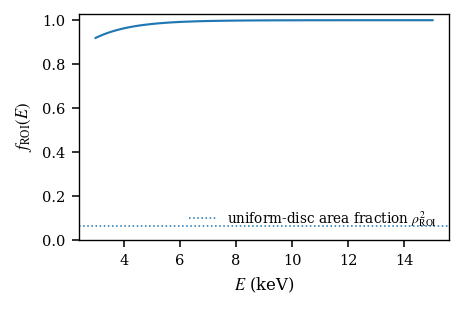

In [18]:
# ==============================================================
# B16-AGSS09 Primakoff flux fraction inside theta_ROI = 4 arcmin
# ==============================================================

ROI_DIR = Path("solar_flux")
ROI_DIR.mkdir(exist_ok=True)

ROI_FRACTION_PATH = ROI_DIR / "primakoff_roi_fraction_B16_AGSS09.csv"

# The supplied SolarAxionFlux result is embedded as a reproducibility
# fallback. If an external CSV is available, it is preferred.
EMBEDDED_ROI_E_KEV = np.array([3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.0, 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9, 5.0, 5.1, 5.2, 5.3, 5.4, 5.5, 5.6, 5.7, 5.8, 5.9, 6.0, 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8, 6.9, 7.0, 7.1, 7.2, 7.3, 7.4, 7.5, 7.6, 7.7, 7.8, 7.9, 8.0, 8.1, 8.2, 8.3, 8.4, 8.5, 8.6, 8.7, 8.8, 8.9, 9.0, 9.1, 9.2, 9.3, 9.4, 9.5, 9.6, 9.7, 9.8, 9.9, 10.0, 10.1, 10.2, 10.3, 10.4, 10.5, 10.6, 10.7, 10.8, 10.9, 11.0, 11.1, 11.2, 11.3, 11.4, 11.5, 11.6, 11.7, 11.8, 11.9, 12.0, 12.1, 12.2, 12.3, 12.4, 12.5, 12.6, 12.7, 12.8, 12.9, 13.0, 13.1, 13.2, 13.3, 13.4, 13.5, 13.6, 13.7, 13.8, 13.9, 14.0, 14.1, 14.2, 14.3, 14.4, 14.5, 14.6, 14.7, 14.8, 14.9, 15.0], dtype=float)

EMBEDDED_ROI_F = np.array([0.9195546211364, 0.9255101674701, 0.9310318796751, 0.9361486887637, 0.9408892822693, 0.9452807218905, 0.9493476106868, 0.9531131836126, 0.9565992833776, 0.9598274980323, 0.9628141862678, 0.9655788051241, 0.9681361245127, 0.9705035485412, 0.9726937280854, 0.9747201520537, 0.9765947724416, 0.9783293123023, 0.9799341650014, 0.9814189195098, 0.9827922510291, 0.9840631889296, 0.985238497796, 0.9863258418108, 0.9873316136041, 0.9882622956473, 0.9892136721304, 0.9900126192303, 0.9907529045815, 0.9914337808394, 0.9920664443206, 0.9926527249542, 0.9931949783962, 0.9936974689286, 0.9941621270401, 0.994593073584, 0.9949915334141, 0.9953606452086, 0.9957064811999, 0.9960222413287, 0.996314750772, 0.9965854315112, 0.9968364001116, 0.9970686308913, 0.9972834942571, 0.99748258667, 0.99766738921, 0.9978378655497, 0.9979960077619, 0.9981425058871, 0.9982783786669, 0.9984041616005, 0.9985209494439, 0.9986288476947, 0.998729129377, 0.9988221070561, 0.9989080960428, 0.9989874631566, 0.9990611372096, 0.9991293698781, 0.9991929113122, 0.9992516207705, 0.9993061315431, 0.9993566673207, 0.999403219472, 0.9994467377934, 0.9994869937751, 0.9995243037294, 0.9995585953775, 0.9995909587572, 0.9996209322162, 0.9996483837463, 0.9996739071748, 0.9996977941014, 0.9997196574392, 0.9997399896789, 0.99975898108, 0.9997763726792, 0.9997926476008, 0.9998077165522, 0.999821596745, 0.9998346124263, 0.999846583267, 0.9998578888431, 0.9998682615225, 0.9998778139848, 0.9998861995524, 0.9998942420392, 0.9999022645352, 0.9999096044198, 0.9999164221694, 0.9999227714569, 0.9999284010981, 0.9999335327888, 0.9999384799595, 0.999942948263, 0.9999475276325, 0.9999510966113, 0.999954833986, 0.9999580455221, 0.9999612765044, 0.9999642295655, 0.9999669351998, 0.9999694137743, 0.9999717340705, 0.9999737605061, 0.999975768733, 0.9999772248154, 0.9999788821884, 0.9999807471219, 0.9999819871395, 0.9999833855079, 0.9999846718398, 0.9999858002828, 0.9999868318809, 0.9999882541442, 0.9999892071415, 0.9999900385517, 0.999990574569, 0.9999915718618, 0.9999922328306], dtype=float)


def _validate_roi_table(tab):
    required = {"E_keV", "f_roi"}
    if not required.issubset(tab.columns):
        raise ValueError("ROI fraction table must contain E_keV,f_roi")

    tab = tab[["E_keV", "f_roi"]].copy()
    tab = tab.sort_values("E_keV").drop_duplicates("E_keV")

    E = tab["E_keV"].to_numpy(float)
    f = tab["f_roi"].to_numpy(float)

    if len(E) < 2:
        raise ValueError("ROI fraction table is too short.")
    if not np.all(np.isfinite(E)) or not np.all(np.isfinite(f)):
        raise ValueError("ROI table contains non-finite values.")
    if np.any((f < 0.0) | (f > 1.0)):
        raise ValueError("ROI fractions must satisfy 0 <= f_roi <= 1.")
    if E.min() > E_MIN or E.max() < E_MAX:
        raise ValueError(f"ROI table must cover {E_MIN}-{E_MAX} keV.")

    return tab


# Search the standard project location first, then the notebook directory.
candidate_paths = [
    ROI_FRACTION_PATH,
    Path("primakoff_roi_fraction_B16_AGSS09.csv"),
]

roi_table = None
ROI_TABLE_ORIGIN = None

for pth in candidate_paths:
    if pth.exists():
        roi_table = _validate_roi_table(pd.read_csv(pth))
        ROI_TABLE_ORIGIN = str(pth)
        break

if roi_table is None:
    roi_table = pd.DataFrame({
        "E_keV": EMBEDDED_ROI_E_KEV,
        "f_roi": EMBEDDED_ROI_F,
    })
    roi_table = _validate_roi_table(roi_table)
    ROI_TABLE_ORIGIN = "embedded SolarAxionFlux B16-AGSS09 table"

    # Write the embedded data into the standard analysis path.
    roi_table.to_csv(ROI_FRACTION_PATH, index=False)

E_roi_tab = roi_table["E_keV"].to_numpy(float)
f_roi_tab = roi_table["f_roi"].to_numpy(float)

_roi_fraction_interp = interp1d(
    E_roi_tab,
    f_roi_tab,
    kind="linear",
    bounds_error=True,
)

ROI_PROFILE_READY = True


def primakoff_roi_fraction(E_keV):
    E = np.asarray(E_keV, dtype=float)
    return np.clip(
        np.asarray(_roi_fraction_interp(E)),
        0.0,
        1.0,
    )


# Flux-weighted ROI fraction across the 3--15 keV Primakoff spectrum.
_Echeck = np.linspace(E_MIN, E_MAX, 1001)
_shape_check = _Echeck**2.481 * np.exp(-_Echeck / 1.205)
ROI_FLUX_FRACTION_3_15 = trapezoid(
    _shape_check * primakoff_roi_fraction(_Echeck),
    _Echeck,
) / trapezoid(_shape_check, _Echeck)

print("=== PRIMAKOFF ROI INPUT ===")
print("Origin                  :", ROI_TABLE_ORIGIN)
print(f"theta_ROI               = {ROI_ARCMIN:.3f} arcmin")
print(f"rho_ROI from geometry   = {RHO_ROI:.6f} R_sun")
print(f"rows                    = {len(roi_table)}")
print(f"f_ROI min/max           = {f_roi_tab.min():.6f} / {f_roi_tab.max():.6f}")
print(f"3--15 keV flux fraction = {ROI_FLUX_FRACTION_3_15:.6f}")
print()

for E in [3.0, 5.0, 8.0, 10.0, 15.0]:
    print(f"E={E:4.1f} keV : f_ROI={float(primakoff_roi_fraction(E)):.8f}")

# Supplemental diagnostic: energy dependence of the adopted ROI fraction.
fig, ax = plt.subplots(figsize=(SINGLE, 2.25))
ax.plot(E_roi_tab, f_roi_tab)
ax.axhline(RHO_ROI**2, ls=":", lw=0.8,
           label=r"uniform-disc area fraction $\rho_{\rm ROI}^2$")
ax.set_xlabel(r"$E$ (keV)")
ax.set_ylabel(r"$f_{\rm ROI}(E)$")
ax.set_ylim(0.0, 1.03)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIGDIR / "Supp_primakoff_roi_fraction.pdf")
fig.savefig(FIGDIR / "Supp_primakoff_roi_fraction.png")
plt.show()


##  Explicit detector benchmark

The sensitivity forecast below is formulated for a **representative LEO focusing X-ray detector**. Every detector ingredient is explicit: effective area $A_{\rm eff}(E)$, a $4'$ source aperture, an aperture-scaled 3--15 keV background, the physical propagated-orbit exposure, expected signal/background counts, and a one-sided 95% C.L. Asimov profile-likelihood construction. Real ARF/PHA products can replace the benchmark arrays without changing the physics pipeline.


In [19]:
# ==============================================================
# Explicit detector model
# ============================================================== 

def solar_axion_flux_total(E_keV, g=GREF):
    """Total Primakoff flux integrated over the full solar image.
    Units: cm^-2 s^-1 keV^-1.
    """
    g10 = g / 1.0e-10
    E = np.asarray(E_keV, dtype=float)
    return 6.02e10 * g10**2 * E**2.481 * np.exp(-E / 1.205)


def solar_axion_flux_roi(E_keV, g=GREF):
    """Primakoff flux restricted to the adopted 4' aperture."""
    return solar_axion_flux_total(E_keV, g) * primakoff_roi_fraction(E_keV)


# Representative combined focusing-telescope effective area [cm^2].
# Replace by ARFs if RESPONSE_MODE='arf'.
EA_E = np.array([3, 4, 5, 6, 8, 10, 12, 15, 20, 30, 50, 78.4], dtype=float)
EA_A = np.array([100, 350, 600, 750, 850, 900, 820, 700, 560, 380, 180, 5], dtype=float)


def area_proxy(E):
    E = np.asarray(E, float)
    return np.maximum(interp1d(EA_E, EA_A, bounds_error=False, fill_value=0)(E), 0.0)


def load_arf_area(paths, E):
    total = np.zeros_like(np.asarray(E, float))
    for path in paths:
        with fits.open(path) as h:
            d = h[1].data
            emid = 0.5 * (d["ENERG_LO"] + d["ENERG_HI"])
            total += np.interp(E, emid, d["SPECRESP"], left=0, right=0)
    return total


def effective_area(E):
    if RESPONSE_MODE == "arf":
        if not ARF_PATHS:
            raise ValueError("RESPONSE_MODE='arf' but ARF_PATHS is empty")
        return load_arf_area(ARF_PATHS, E)
    return area_proxy(E)


# Circular source aperture.
ROI_AREA_ARCMIN2 = np.pi * ROI_ARCMIN**2
ROI_AREA_REF_ARCMIN2 = np.pi * ROI_RADIUS_REF_ARCMIN**2

# Convert the reference total aperture background to an integrated surface rate.
BKG_SURF_TOTAL_3_15 = BKG_TOTAL_3_15_REF / ROI_AREA_REF_ARCMIN2  # count s^-1 arcmin^-2


def background_shape(E):
    """Dimensionless benchmark spectral shape over the analysis band."""
    E = np.asarray(E, float)
    return 0.7 + 0.3 * (E / 10.0)


def background_differential(E):
    """Aperture-integrated background spectrum [count s^-1 keV^-1]."""
    E = np.asarray(E, float)
    shape = background_shape(E)
    norm = trapezoid(shape, E)
    return BKG_SURF_TOTAL_3_15 * ROI_AREA_ARCMIN2 * shape / norm


print("=== DETECTOR BENCHMARK ===")
print(f"ROI radius              = {ROI_ARCMIN:.2f} arcmin")
print(f"ROI area                = {ROI_AREA_ARCMIN2:.3f} arcmin^2")
print(f"Background 3-15 keV     = {BKG_SURF_TOTAL_3_15*ROI_AREA_ARCMIN2:.3e} count/s")
print(f"Physical occultation    = {T_valid:.1f} s")


=== DETECTOR BENCHMARK ===
ROI radius              = 4.00 arcmin
ROI area                = 50.265 arcmin^2
Background 3-15 keV     = 2.000e-03 count/s
Physical occultation    = 470.0 s


##  Orbit-integrated expected counts and 95% C.L. sensitivity

For each axion mass the signal is integrated over both energy and the **propagated lunar-occulted orbit**, not a static 300-s shell point:

\[
S_{\rm ref}(m_a)=\int_{\rm occ}dt\int dE\,
A_{\rm eff}(E)\,\frac{d\Phi_a^{\rm ROI}}{dE}\,
P_{a\to\gamma}(E,m_a,t;g_{\rm ref}).
\]

Since Primakoff production and regeneration each scale as $g_{a\gamma}^2$, $S(g)=S_{\rm ref}(g/g_{\rm ref})^4$. For an expected one-sided 95% C.L. upper limit under the background-only Asimov data set we use

\[
q_{\mu,A}=2\left[S-B\ln\left(1+S/B\right)\right],
\]

and solve $q_{\mu,A}=2.71$. In the zero-background limit this approaches $q_{\mu,A}=2S$.


In [20]:
# ==============================================================
# Orbit-integrated signal and likelihood
# ============================================================== 

E_SIGNAL = np.linspace(E_MIN, E_MAX, N_E)

# Use every 50 s in FAST mode, every 10 s in the final run.
TIME_STRIDE = 5 if FAST else 1
_t_all = np.asarray(t_valid, float)
t_signal = _t_all[::TIME_STRIDE]
if t_signal[-1] != _t_all[-1]:
    t_signal = np.r_[t_signal, _t_all[-1]]


def build_signal_orbit_profiles(Kp=KP_FID):
    profiles = []
    for j, dt in enumerate(t_signal):
        t = time_from_dt(float(dt))
        r_sat, _ = orbit_state(float(dt))
        profiles.append(
            build_field_profile_from_state(
                t,
                r_sat,
                Kp=Kp,
                npts=(220 if FAST else N_FIELD),
            )
        )
        if j % max(1, len(t_signal)//5) == 0:
            print(f"  orbit-profile cache Kp={Kp}: {j+1}/{len(t_signal)}")
    return profiles


def signal_counts_orbit(ma, profiles, plasma_model=PLASMA_FID):
    """Reference counts at GREF, integrated over physical orbit and energy."""
    rates_t = []
    for profile in profiles:
        P = np.array([
            probability_from_profile(
                profile,
                ma_eV=ma,
                E_keV=E,
                g=GREF,
                plasma_model=plasma_model,
                phase_step=PHASE_STEP,
            )
            for E in E_SIGNAL
        ])
        spec = solar_axion_flux_roi(E_SIGNAL, GREF) * P * effective_area(E_SIGNAL)
        rates_t.append(trapezoid(spec, E_SIGNAL))
    return trapezoid(np.asarray(rates_t), t_signal)


def background_counts_orbit():
    bkg_rate = trapezoid(background_differential(E_SIGNAL), E_SIGNAL)
    return bkg_rate * (t_signal[-1] - t_signal[0])


def qmu_asimov_bonly(S, B):
    """One-sided Asimov exclusion statistic for n_A=B."""
    S = float(max(S, 0.0))
    B = float(max(B, 0.0))
    if S == 0.0:
        return 0.0
    if B <= 0.0:
        return 2.0 * S
    return 2.0 * (S - B * np.log1p(S / B))


def expected_limit_from_reference(Sref, B, qtarget=2.71):
    if not np.isfinite(Sref) or Sref <= 0:
        return np.nan

    def f(log10g):
        g = 10.0**log10g
        S = Sref * (g / GREF)**4
        return qmu_asimov_bonly(S, B) - qtarget

    lo, hi = np.log10(1e-13), np.log10(3e-9)
    if f(lo) >= 0:
        return 10.0**lo
    if f(hi) <= 0:
        return np.nan
    return 10.0**brentq(f, lo, hi)


if ROI_PROFILE_READY:
    print("Building propagated-orbit magnetic profiles for the sensitivity...")
    SIGNAL_PROFILES = build_signal_orbit_profiles(KP_FID)
    BEXP = background_counts_orbit()
    print(f"Sensitivity time samples = {len(t_signal)}")
    print(f"Exposure represented     = {t_signal[-1]-t_signal[0]:.1f} s")
    print(f"Expected background      = {BEXP:.4f} counts")
else:
    SIGNAL_PROFILES = None
    BEXP = np.nan
    print("Sensitivity waiting for the B16-AGSS09 ROI fraction table.")


Building propagated-orbit magnetic profiles for the sensitivity...
  orbit-profile cache Kp=2: 1/48
  orbit-profile cache Kp=2: 10/48
  orbit-profile cache Kp=2: 19/48
  orbit-profile cache Kp=2: 28/48
  orbit-profile cache Kp=2: 37/48
  orbit-profile cache Kp=2: 46/48
Sensitivity time samples = 48
Exposure represented     = 470.0 s
Expected background      = 0.9400 counts


## MAIN FIGURE 3 — propagated-orbit sensitivity benchmark

This plotting pipeline uses the physical August orbit, the $4'$ B16-AGSS09 Primakoff ROI fraction, the explicit effective-area model, the aperture background, and a one-sided 95% C.L. Asimov likelihood. The **orbital and ROI treatment is final in structure**, while the detector response/background remain benchmark inputs 



  1/75  ma=1.000e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  2/75  ma=1.205e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  3/75  ma=1.453e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  4/75  ma=1.751e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  5/75  ma=2.110e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  6/75  ma=2.543e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  7/75  ma=3.065e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  8/75  ma=3.695e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
  9/75  ma=4.453e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
 10/75  ma=5.367e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
 11/75  ma=6.469e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
 12/75  ma=7.796e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
 13/75  ma=9.397e-10 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
 14/75  ma=1.133e-09 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
 15/75  ma=1.365e-09 eV  Sref=8.7171e-01  g95=1.3144e-10 GeV^-1
 16/75  ma=1.645e-09 eV  Sref=8.7171e-01

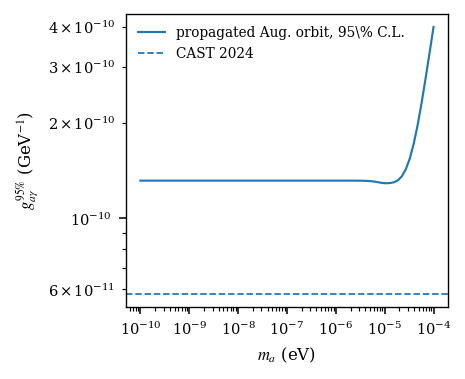

In [21]:
# ==============================================================
# MAIN FIGURE 3 — expected 95% CL sensitivity
# ============================================================== 

masses = np.logspace(-10, np.log10(MASS_MAX), 28 if FAST else N_MASS)
CAST_2024 = 5.8e-11

SREF = None
GSENS = None

if ROI_PROFILE_READY:
    SREF = np.empty_like(masses)
    GSENS = np.empty_like(masses)

    for i, ma in enumerate(masses):
        SREF[i] = signal_counts_orbit(ma, SIGNAL_PROFILES)
        GSENS[i] = expected_limit_from_reference(SREF[i], BEXP, qtarget=2.71)
        print(
            f"{i+1:3d}/{len(masses)}  "
            f"ma={ma:.3e} eV  "
            f"Sref={SREF[i]:.4e}  "
            f"g95={GSENS[i]:.4e} GeV^-1"
        )

    # Low-mass count benchmark at the reference coupling.
    print()
    print("=== LOW-MASS BENCHMARK ===")
    print(f"S(g_ref) = {SREF[0]:.5f} counts")
    print(f"B        = {BEXP:.5f} counts")
    print(f"g_95     = {GSENS[0]:.5e} GeV^-1")

    fig, ax = plt.subplots(figsize=(SINGLE, 2.75))
    ax.loglog(
        masses,
        GSENS,
        label=r"propagated Aug. orbit, 95\% C.L.",
    )
    ax.axhline(
        CAST_2024,
        ls="--",
        lw=0.9,
        label=r"CAST 2024",
    )

    ax.set_xlabel(r"$m_a$ (eV)")
    ax.set_ylabel(r"$g_{a\gamma}^{95\%}$ (GeV$^{-1}$)")
    ax.legend(frameon=False, loc="best")
    fig.tight_layout()

    fig.savefig(FIGDIR / "Fig3_sensitivity_propagated_orbit.pdf")
    fig.savefig(FIGDIR / "Fig3_sensitivity_propagated_orbit.png")
    plt.show()
else:
    print("Fig. 3 not evaluated: supply the B16-AGSS09 ROI flux table first.")


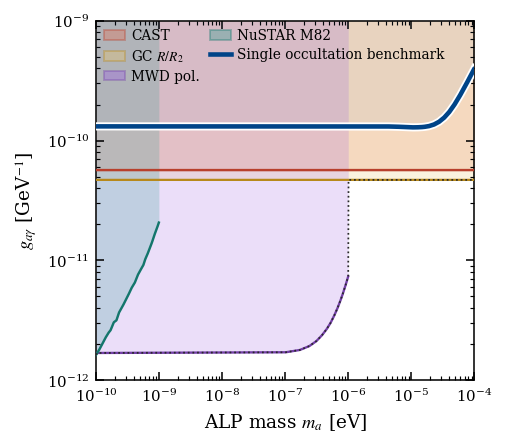

In [22]:
# ==============================================================
# FIG. 3 — AXION PARAMETER-SPACE EXCLUSION PLOT
# ==============================================================


# --------------------------------------------------------------
# AxionLimits data
# --------------------------------------------------------------

LIMITDIR = Path("limit_data")
LIMITDIR.mkdir(exist_ok=True)

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "cajohare/AxionLimits/master/"
    "limit_data/AxionPhoton/"
)

LIMIT_FILES = {
    "CAST": "CAST.txt",
    "GC":   "GlobularClusters.txt",
    "MWD":  "MWDPolarisation_KeckLick.txt",
    "M82":  "M82.txt",
}


def load_axion_limit(filename):
    """
    Download an AxionLimits table once and cache locally.
    Returns mass [eV], g_agamma [GeV^-1].
    """

    path = LIMITDIR / filename

    if not path.exists():
        print(f"Downloading {filename}...")
        urlretrieve(BASE_URL + filename, path)

    dat = np.loadtxt(path)

    x = np.asarray(dat[:, 0], dtype=float)
    y = np.asarray(dat[:, 1], dtype=float)

    mask = (
        np.isfinite(x)
        & np.isfinite(y)
        & (x > 0.0)
        & (y > 0.0)
    )

    x = x[mask]
    y = y[mask]

    return x, y


def log_interpolate_limit(x, y, mgrid):
    """
    Log-log interpolation onto mgrid.

    Important:
    we interpolate FIRST and only afterwards restrict to the
    plotting interval. This avoids losing CAST in the low-mass
    plateau.
    """

    order = np.argsort(x)
    x = x[order]
    y = y[order]

    # Remove repeated masses if they occur.
    xu, idx = np.unique(x, return_index=True)
    yu = y[idx]

    out = np.full_like(mgrid, np.nan, dtype=float)

    valid = (
        (mgrid >= xu.min())
        & (mgrid <= xu.max())
    )

    out[valid] = 10.0 ** np.interp(
        np.log10(mgrid[valid]),
        np.log10(xu),
        np.log10(yu)
    )

    return out


# --------------------------------------------------------------
# Load limits
# --------------------------------------------------------------

x_cast, y_cast = load_axion_limit(LIMIT_FILES["CAST"])
x_gc,   y_gc   = load_axion_limit(LIMIT_FILES["GC"])
x_mwd,  y_mwd  = load_axion_limit(LIMIT_FILES["MWD"])
x_m82,  y_m82  = load_axion_limit(LIMIT_FILES["M82"])


# --------------------------------------------------------------
# Fine common mass grid
# --------------------------------------------------------------

xmin = masses.min()
xmax = masses.max()

mplot = np.logspace(
    np.log10(xmin),
    np.log10(xmax),
    1200
)


CAST = log_interpolate_limit(
    x_cast, y_cast, mplot
)

GC = log_interpolate_limit(
    x_gc, y_gc, mplot
)

MWD = log_interpolate_limit(
    x_mwd, y_mwd, mplot
)

M82 = log_interpolate_limit(
    x_m82, y_m82, mplot
)


# Interpolate our sensitivity to the same fine grid
GOOD = (
    np.isfinite(GSENS)
    & (GSENS > 0)
)

OUR = 10.0 ** np.interp(
    np.log10(mplot),
    np.log10(masses[GOOD]),
    np.log10(GSENS[GOOD])
)


# --------------------------------------------------------------
# Current best envelope
# --------------------------------------------------------------

existing_limits = np.vstack([
    CAST,
    GC,
    MWD,
    M82,
])

CURRENT_BEST = np.nanmin(
    existing_limits,
    axis=0
)


# --------------------------------------------------------------
# Plot limits
# --------------------------------------------------------------
#
# These can be manually modified if needed.
# The automatic lower range guarantees that the strongest
# constraint and our sensitivity are visible.
# --------------------------------------------------------------

all_low_values = [
    np.nanmin(OUR),
    np.nanmin(CAST),
    np.nanmin(GC),
    np.nanmin(MWD),
    np.nanmin(M82),
]

raw_ymin = np.nanmin(all_low_values)

YMIN = 10.0 ** np.floor(
    np.log10(raw_ymin) - 0.15
)

# Usually 10^-9 is visually good for this mass range.
# Increase if your sensitivity becomes worse at high mass.
YMAX = max(
    1.0e-9,
    2.0 * np.nanmax(OUR)
)

YMAX = 10.0 ** np.ceil(
    np.log10(YMAX)
)


# --------------------------------------------------------------
#  style
# --------------------------------------------------------------

plt.rcParams.update({

    "font.family": "serif",
    "mathtext.fontset": "stix",

    "font.size": 8.5,

    "axes.labelsize": 9.5,
    "axes.linewidth": 0.8,

    "xtick.labelsize": 7.7,
    "ytick.labelsize": 7.7,

    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.top": True,
    "ytick.right": True,

    "xtick.major.size": 4.0,
    "ytick.major.size": 4.0,

    "xtick.minor.size": 2.2,
    "ytick.minor.size": 2.2,

    "legend.fontsize": 7.0,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# A little taller than before:
# parameter-space plots benefit from vertical space.
fig, ax = plt.subplots(
    figsize=(3.40, 3.15)
)


# ==============================================================
# EXISTING EXCLUSIONS
# ==============================================================

# --------------------------------------------------------------
# CAST
# --------------------------------------------------------------

mask = np.isfinite(CAST)

ax.fill_between(
    mplot[mask],
    CAST[mask],
    YMAX,
    color="#e76f51",
    alpha=0.22,
    linewidth=0,
    zorder=1,
)

ax.plot(
    mplot[mask],
    CAST[mask],
    color="#b8402c",
    lw=1.25,
    zorder=6,
)


# --------------------------------------------------------------
# Globular clusters
# --------------------------------------------------------------

mask = np.isfinite(GC)

ax.fill_between(
    mplot[mask],
    GC[mask],
    YMAX,
    color="#e9c46a",
    alpha=0.22,
    linewidth=0,
    zorder=1.1,
)

ax.plot(
    mplot[mask],
    GC[mask],
    color="#b7891b",
    lw=1.15,
    zorder=6,
)


# --------------------------------------------------------------
# Magnetic white dwarf polarization
# --------------------------------------------------------------

mask = np.isfinite(MWD)

ax.fill_between(
    mplot[mask],
    MWD[mask],
    YMAX,
    color="#9b5de5",
    alpha=0.20,
    linewidth=0,
    zorder=1.2,
)

ax.plot(
    mplot[mask],
    MWD[mask],
    color="#7440a8",
    lw=1.2,
    zorder=6,
)


# --------------------------------------------------------------
# NuSTAR M82
# --------------------------------------------------------------

mask = np.isfinite(M82)

ax.fill_between(
    mplot[mask],
    M82[mask],
    YMAX,
    color="#2a9d8f",
    alpha=0.22,
    linewidth=0,
    zorder=1.3,
)

ax.plot(
    mplot[mask],
    M82[mask],
    color="#14766c",
    lw=1.25,
    zorder=7,
)


# ==============================================================
# THIS WORK
# ==============================================================

# --------------------------------------------------------------
# Very faint region that could be excluded by this experiment
# under the background-only hypothesis.
# --------------------------------------------------------------

ax.fill_between(
    mplot,
    OUR,
    YMAX,
    color="#2774c8",
    alpha=0.060,
    linewidth=0,
    zorder=2,
)


# --------------------------------------------------------------
# Genuinely NEW parameter space
#
# Only shade where our expected sensitivity is stronger
# than the best existing constraint.
# --------------------------------------------------------------

new_space = (
    np.isfinite(OUR)
    & np.isfinite(CURRENT_BEST)
    & (OUR < CURRENT_BEST)
)

ax.fill_between(
    mplot,
    OUR,
    CURRENT_BEST,
    where=new_space,
    interpolate=True,
    color="#2774c8",
    alpha=0.32,
    linewidth=0,
    zorder=3,
)


# White halo under our sensitivity curve
ax.plot(
    mplot,
    OUR,
    color="white",
    lw=4.2,
    zorder=9,
)


# Main sensitivity curve
ax.plot(
    mplot,
    OUR,
    color="#004488",
    lw=2.35,
    zorder=10,
    solid_capstyle="round",
)


# ==============================================================
# CURRENT BEST ENVELOPE
# ==============================================================

# Optional: this makes visually obvious where the presently
# excluded/allowed boundary actually lies.

ax.plot(
    mplot,
    CURRENT_BEST,
    color="0.16",
    lw=0.9,
    ls=":",
    zorder=8,
)


# ==============================================================
# AXES
# ==============================================================

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlim(
    xmin,
    xmax
)

ax.set_ylim(
    YMIN,
    YMAX
)

ax.set_xlabel(
    r"ALP mass $m_a$ [eV]"
)

ax.set_ylabel(
    r"$g_{a\gamma}$ [GeV$^{-1}$]"
)


# Minor logarithmic ticks
ax.xaxis.set_minor_locator(
    LogLocator(
        base=10,
        subs=np.arange(2, 10) * 0.1
    )
)

ax.yaxis.set_minor_locator(
    LogLocator(
        base=10,
        subs=np.arange(2, 10) * 0.1
    )
)

ax.xaxis.set_minor_formatter(
    NullFormatter()
)

ax.yaxis.set_minor_formatter(
    NullFormatter()
)


# ==============================================================
# TEXT
# ==============================================================

"""ax.text(
    0.50,
    0.73,
    r"Expected 95 % C.L.",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=7.3,
    color="#004488",
    zorder=20,
)"""

"""ax.text(
    0.97,
    0.96,
    "Excluded",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=7.5,
    color="0.25",
    zorder=20,
)"""


# ==============================================================
# LEGEND
# ==============================================================

handles = [

    Patch(
        facecolor="#e76f51",
        edgecolor="#b8402c",
        alpha=0.35,
        label="CAST"
    ),

    Patch(
        facecolor="#e9c46a",
        edgecolor="#b7891b",
        alpha=0.35,
        label=r"GC $R/R_2$"
    ),


    Patch(
        facecolor="#9b5de5",
        edgecolor="#7440a8",
        alpha=0.35,
        label="MWD pol."
    ),

    Patch(
        facecolor="#2a9d8f",
        edgecolor="#14766c",
        alpha=0.35,
        label=r"NuSTAR M82"
    ),

    Line2D(
        [0],
        [0],
        color="#004488",
        lw=2.35,
        label="Single occultation benchmark"
        ),
]


ax.legend(
    handles=handles,
    loc="upper left",
    frameon=False,
    ncol=2,
    columnspacing=0.8,
    handlelength=1.5,
    handletextpad=0.45,
    borderpad=0.1,
    labelspacing=0.35,
)


# ==============================================================
# FINAL LAYOUT
# ==============================================================

fig.subplots_adjust(
    left=0.19,
    right=0.985,
    bottom=0.17,
    top=0.985
)

fig.savefig(
    FIGDIR / "Fig3_axion_parameter_space.pdf",
    bbox_inches="tight"
)

fig.savefig(
    FIGDIR / "Fig3_axion_parameter_space.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## Supplemental signal/background spectrum


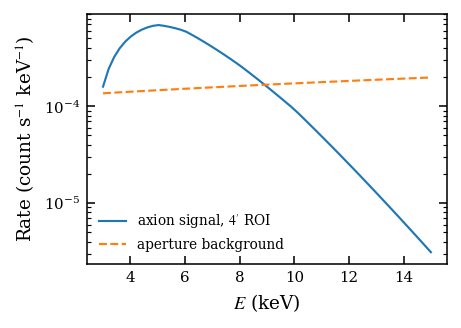

In [23]:
if ROI_PROFILE_READY:
    ma_demo = 1e-8
    P_demo = np.array([
        probability_from_profile(PROFILE_FIG2, ma_demo, E, g=GREF)
        for E in E_SIGNAL
    ])
    sig_rate = solar_axion_flux_roi(E_SIGNAL, GREF) * P_demo * effective_area(E_SIGNAL)
    bkg_rate = background_differential(E_SIGNAL)

    fig, ax = plt.subplots(figsize=(SINGLE, 2.40))
    ax.semilogy(E_SIGNAL, sig_rate, label=r"axion signal, $4'$ ROI")
    ax.semilogy(E_SIGNAL, bkg_rate, ls="--", label=r"aperture background")
    ax.set_xlabel(r"$E$ (keV)")
    ax.set_ylabel(r"Rate (count s$^{-1}$ keV$^{-1}$)")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGDIR / "Supp_signal_background.pdf")
    fig.savefig(FIGDIR / "Supp_signal_background.png")
    plt.show()
else:
    print("Supplemental signal/background spectrum waiting for ROI flux table.")


## Optional line-of-sight systematics — Supplemental

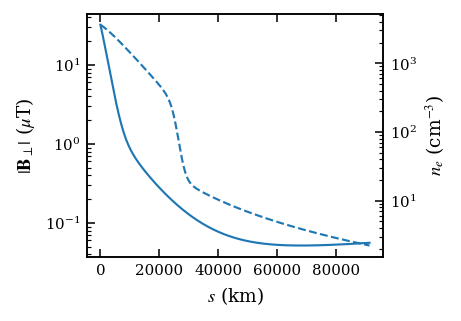

In [24]:
p=FIELD[KP_FID]
ne=electron_density_cm3(p["r_re"],KP_FID,PLASMA_FID)

fig,ax=plt.subplots(figsize=(SINGLE,2.35))
ax.semilogy(p["s_m"]/1e3,p["Bperp_mag_T"]*1e6,label=r"$|\mathbf{B}_\perp|$")
ax.set_xlabel(r"$s$ (km)")
ax.set_ylabel(r"$|\mathbf{B}_\perp|$ ($\mu$T)")

ax2=ax.twinx()
ax2.semilogy(p["s_m"]/1e3,ne,ls="--",label=r"$n_e$")
ax2.set_ylabel(r"$n_e$ (cm$^{-3}$)")

fig.tight_layout()
fig.savefig(FIGDIR/"Supp_LOS_field_plasma.pdf")
fig.savefig(FIGDIR/"Supp_LOS_field_plasma.png")
plt.show()


##  Export machine-readable data

In [25]:
# ==============================================================
# Export machine-readable results
# ============================================================== 

ORBIT_RESULT.to_csv("propagated_orbit_IB.csv", index=False)

if ROI_PROFILE_READY:
    roi_table.to_csv("primakoff_roi_fraction.csv", index=False)

if isinstance(GSENS, np.ndarray):
    pd.DataFrame({
        "ma_eV": masses,
        "Sref_counts_at_g1e-10": SREF,
        "g95_GeVinv": GSENS,
    }).to_csv("sensitivity_data.csv", index=False)
else:
    print("Sensitivity CSV not written: ROI flux table still missing.")

print("Figures:", FIGDIR.resolve())


Figures: /home/duvier/physic/axion_moon_preliminary/Repo-axion-moon/figures
